In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#***1***
<p>Open a new notebook 'auto_subplots.ipynb', load 'auto_trips.csv' with `parse_dates=['trip_date']`, and build a 2x2 grid with `plt.subplots(2, 2, figsize=(12, 8))` showing daily total fare, distance vs fare, trips per area and a fare histogram, each with its own title. Call `tight_layout()` and save 'trip_grid.png'. Hint: Missed Session 10? Generate 600 trips with fare = 30 + 14 x distance plus noise and save 'auto_trips.csv' first.</p>


In [3]:
df = pd.read_csv('auto_trips.csv', parse_dates=['trip_date'])

Text(0.5, 1.0, 'Fare Histogram')

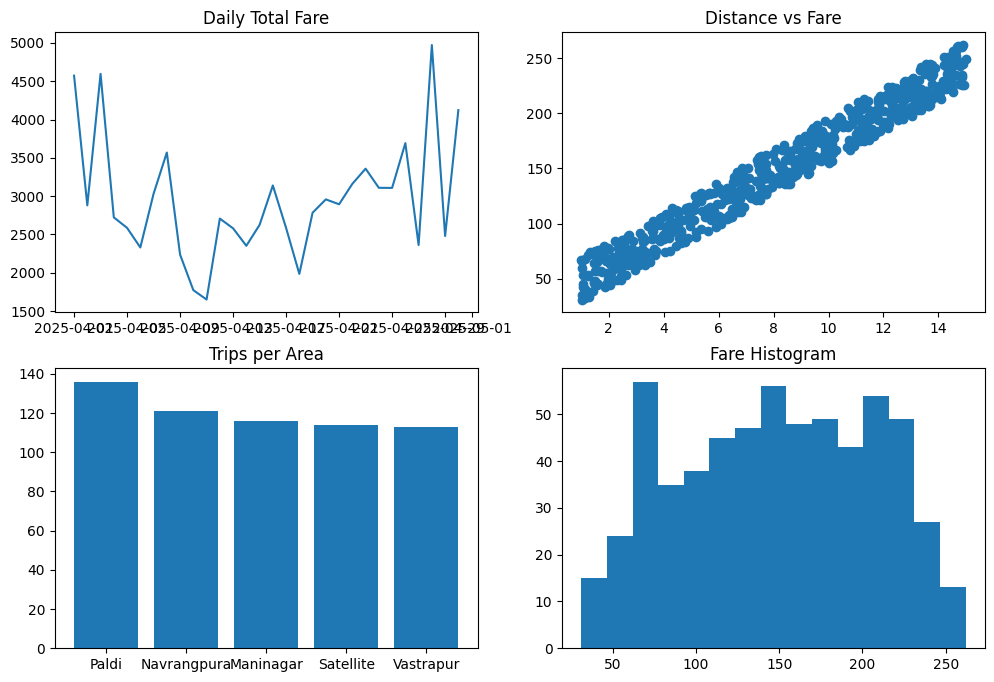

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

daily = df.groupby('trip_date')['fare_inr'].sum()
ax[0,0].plot(daily)
ax[0,0].set_title('Daily Total Fare')

ax[0,1].scatter(df['distance_km'], df['fare_inr'])
ax[0,1].set_title('Distance vs Fare')

area = df['area'].value_counts()
ax[1,0].bar(area.index, area.values)
ax[1,0].set_title('Trips per Area')

ax[1,1].hist(df['fare_inr'], bins=15)
ax[1,1].set_title('Fare Histogram')

In [5]:
plt.tight_layout()

plt.savefig('trip_grid.png')

plt.show()

<Figure size 640x480 with 0 Axes>

#***3***

<p>Plot the fare distribution of each area as box plots in one axes with `ax.boxplot`, using five lists built with a list comprehension and `df.loc`, and label the x ticks with the area names. Save it as 'fare_by_area_box.png'. Hint: Call `ax.set_xticklabels(areas)` after drawing. Constraint: Do not use `groupby` or Seaborn.</p>



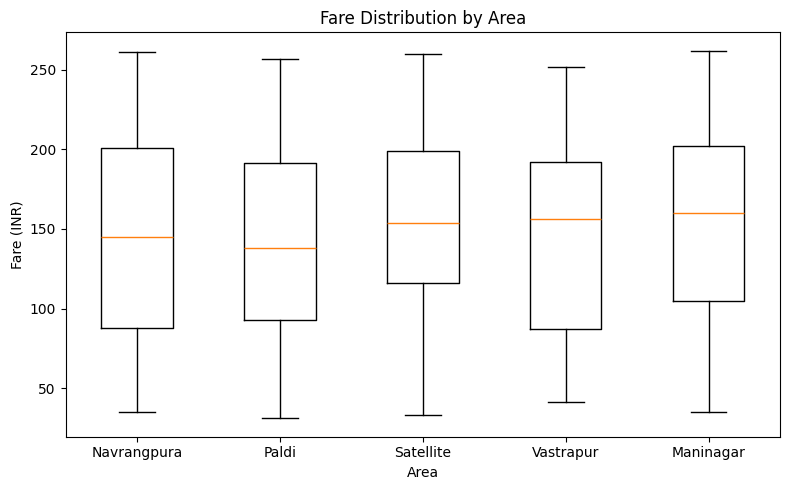

In [8]:
areas = df['area'].unique()
fare_list = [df.loc[df['area'] == area, 'fare_inr'] for area in areas]
fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(fare_list)
ax.set_xticklabels(areas)

ax.set_title('Fare Distribution by Area')
ax.set_xlabel('Area')
ax.set_ylabel('Fare (INR)')

plt.tight_layout()
plt.savefig('fare_by_area_box.png')
plt.show()

#***4***
<p>Draw the daily total fare line again, mark the highest-fare day with `ax.annotate` and an arrow, write its fare with `ax.text`, and add the average daily total as a dashed `ax.axhline`. Assert the annotated date equals the `idxmax()` of the daily series and save 'fare_peak_annotated.png'. Run Restart & Run All and push to 's11_auto_subplots' in your GitHub repo 'ds_analysis_portfolio'.</p>


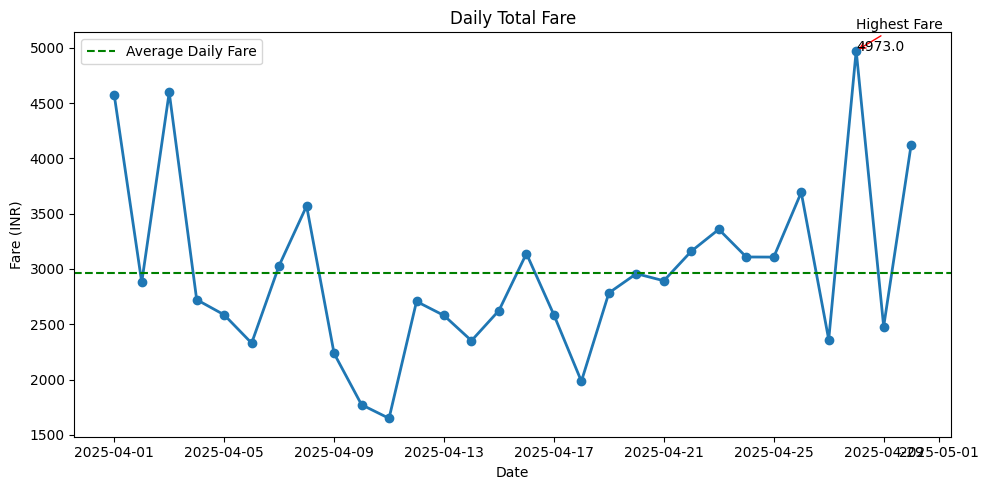

In [11]:

df['trip_date'] = pd.to_datetime(df['trip_date'])

daily = df.set_index('trip_date')['fare_inr'].resample('D').sum()

peak_date = daily.idxmax()
peak_fare = daily.max()

assert peak_date == daily.idxmax()
avg_fare = daily.mean()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(daily.index, daily.values, linewidth=2, marker='o')

ax.annotate('Highest Fare',
            xy=(peak_date, peak_fare),
            xytext=(peak_date, peak_fare + 200),
            arrowprops=dict(arrowstyle='->', color='red'))

ax.text(peak_date, peak_fare, str(round(peak_fare, 2)))

ax.axhline(avg_fare, color='green', linestyle='--',
           label='Average Daily Fare')

ax.set_title('Daily Total Fare')
ax.set_xlabel('Date')
ax.set_ylabel('Fare (INR)')
ax.legend()

plt.tight_layout()
plt.savefig('fare_peak_annotated.png')
plt.show()